# Customer Loyalty Prediction: Modeling the Relationship Between Spending Patterns and Customer Loyalty

In [1]:
# Importing packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.formula.api import ols, logit

import pickle
import os

### Question 4

4. Are high spenders actually more loyal?
Churn falls as spend rises, from about 83% in the lowest spend quintile to about 66% in the highest. You could explore whether this holds within each plan, or whether spend is just a proxy for plan tier. That tells you if upselling reduces churn or just reflects who was already loyal.

In [3]:
dataset = '../data/customer_churn_clean.csv'
df = pd.read_csv(dataset)
df.head()

,Unnamed: 0,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,0,10001,Male,East,Basic,PayPal,27.0,27,1.0,61.08,0
1,1,10002,NaN,West,Pro,PayPal,55.0,146,2.0,73.09,0
2,2,10003,Female,West,Pro,E-Wallet,NaN,147,2.0,116.30,1
3,3,10004,Female,South,Basic,Credit Card,NaN,34,1.0,0.58,1
4,4,10005,Male,North,Basic,Crypto,30.0,146,3.0,46.35,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              10000 non-null  int64  
 1   customer_id             10000 non-null  int64  
 2   gender                  9039 non-null   str    
 3   region                  10000 non-null  str    
 4   subscription_plan       10000 non-null  str    
 5   payment_method          9300 non-null   str    
 6   age                     8491 non-null   float64
 7   days_since_last_login   10000 non-null  int64  
 8   customer_service_calls  9950 non-null   float64
 9   monthly_spend           9441 non-null   float64
 10  churn                   10000 non-null  int64  
dtypes: float64(3), int64(4), str(4)
memory usage: 859.5 KB


#### Analysis Variables
* Subscription Plan
    - customer's current service tier
* Monthly Spend
    - average monthly revenue
* Churn
    - Taget variable. 1 = Churned, 0 = Retained

**_Objectives_**
* Identify the relationship between revenue and churn
* Diagnose if revenue is a proxy for subscription plan
* Churn ~ Revenue analysis given that revenue is the main driver of attrition

In [5]:
# Subsetting analysis variables
subset = df[['subscription_plan','monthly_spend','churn']].dropna().copy()
subset.head()

,subscription_plan,monthly_spend,churn
0,Basic,61.08,0
1,Pro,73.09,0
2,Pro,116.30,1
3,Basic,0.58,1
4,Basic,46.35,1


In [16]:
# Isolating zero spenders to the analysis
# Zero spenders doesn't produce significant revenue for the analysis
non_zero = subset[subset.monthly_spend>0].copy()
non_zero.head()

,subscription_plan,monthly_spend,churn
0,Basic,61.08,0
1,Pro,73.09,0
2,Pro,116.30,1
3,Basic,0.58,1
4,Basic,46.35,1


In [64]:
non_zero[['subscription_plan','churn']].value_counts(normalize=True)*100

subscription_plan  churn
Basic              1        33.767787
Pro                1        26.138945
Plus               1        15.329427
Basic              0         8.645223
Pro                0         8.537606
Plus               0         7.581012
Name: proportion, dtype: float64

In [68]:
# Creating a table of revenue per subscription plan
# Grouped by churn status
revenue_table = non_zero.groupby(['subscription_plan','churn']).agg(
    total_subs=('subscription_plan','count'),
    avg_revenue=('monthly_spend','mean'),
    total_revenue=('monthly_spend','sum')
).sort_values(by='churn').reset_index()
revenue_table

,subscription_plan,churn,total_subs,avg_revenue,total_revenue
0,Basic,0,723,49.734288,35957.89
1,Plus,0,634,163.985521,103966.82
2,Pro,0,714,94.298725,67329.29
3,Basic,1,2824,44.381941,125334.60
4,Plus,1,1282,157.239750,201581.36
5,Pro,1,2186,83.908843,183424.73


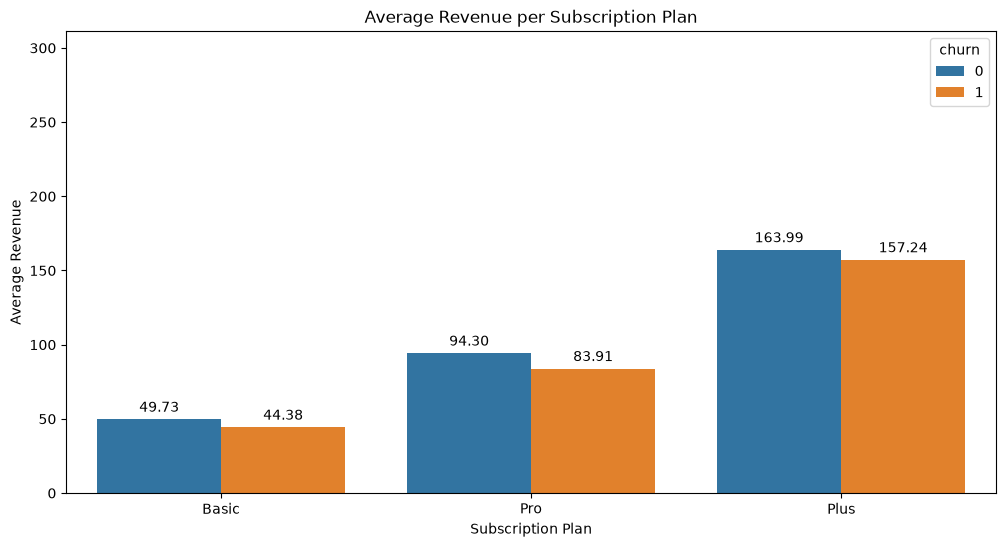

In [44]:
# Visualizing average revenue per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    x='subscription_plan',
    y='monthly_spend',
    data=non_zero,
    hue='churn',
    ax=ax,
    errorbar=None
)
for p in p.patches:
    if p.get_height() > 0:
        height=p.get_height()
        ax.annotate(
            f'{height:.2f}',
            xy=(p.get_x()+p.get_width()/2, height),
            xytext=(0,3),
            textcoords='offset points',
            ha='center',
            va='bottom'
        )
plt.ylabel('Average Revenue')
plt.xlabel('Subscription Plan')
plt.title('Average Revenue per Subscription Plan')
plt.ylim(0, non_zero.monthly_spend.max()*1)
plt.show()


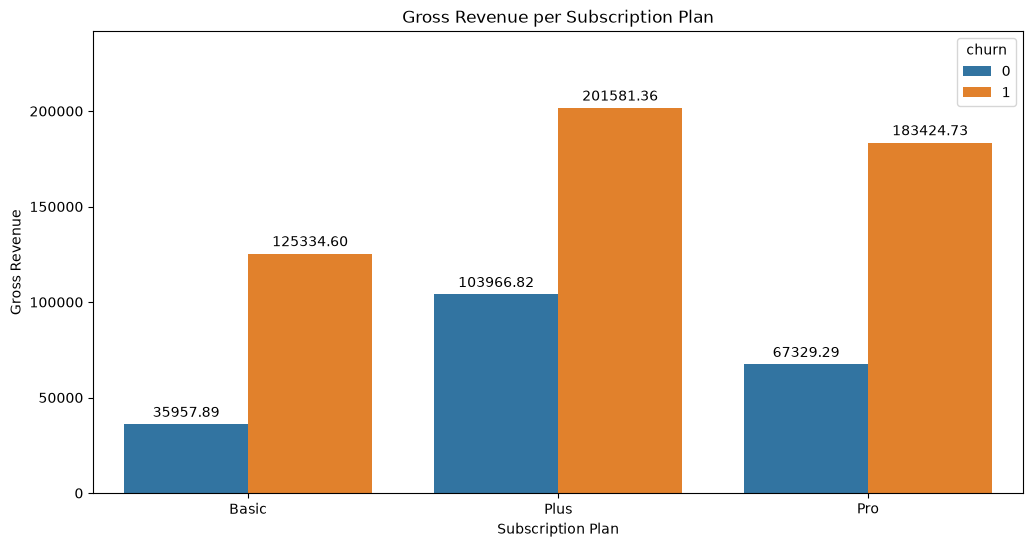

In [42]:
# Visualizing total revenue per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    x='subscription_plan',
    y='total_revenue',
    data=revenue_table,
    hue='churn',
    ax=ax,
    errorbar=None
)
for p in p.patches:
    if p.get_height() > 0:
        height=p.get_height()
        ax.annotate(
            f'{height:.2f}',
            xy=(p.get_x()+p.get_width()/2, height),
            xytext=(0,3),
            textcoords='offset points',
            ha='center',
            va='bottom'
        )
plt.ylabel('Gross Revenue')
plt.xlabel('Subscription Plan')
plt.title('Gross Revenue per Subscription Plan')
plt.ylim(0, revenue_table.total_revenue.max()*1.2)
plt.show()


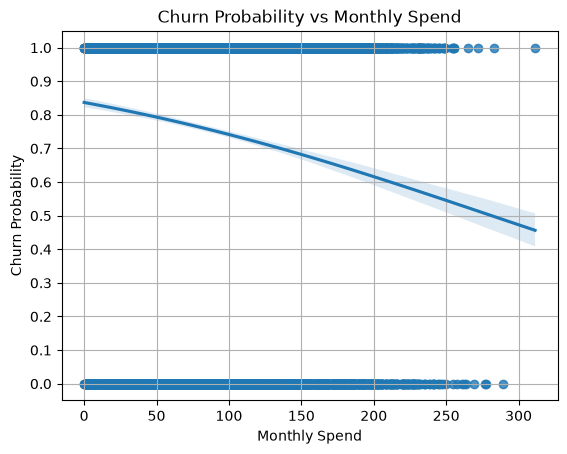

In [49]:
# Visualizing the trend line of revenue per subscription plan
sns.regplot(
    x='monthly_spend',
    y='churn',
    data=non_zero,
    logistic=True
)
plt.ylabel('Churn Probability')
plt.xlabel('Monthly Spend')
plt.title('Churn Probability vs Monthly Spend')
plt.yticks(np.arange(0,1.1,0.1))
plt.grid()
plt.show()

**_Initial Findings_**
* Results shows that:
    1. Retained customers have $5-$10 higher average spendings compared to churned customers
    2. High generated revenue by churned users is mainly driven by its large proportion of customers
    3. There is a negative relationship between monthly spend and churn rate, indicating that higher spendings leads to higher retention rate

**_Next Steps_**
* Structuring
    - Categorizing monthly spend to low, moderate, and high spenders
* Hypothesis Testing
    - Perform hypothesis testing to support the initial findings that there is a negative relationship between churn and monthly spend
    - Perform second hypothesis testing to determine which variable between monthly spend or subcription plan is the main driver of customer churn. This answers the question: Is revenue a proxy of subscription plan?